# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module – Research Assignment**

This notebook implements recursive spectral modularity partitioning from scratch (NumPy + NetworkX only),
following Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582.
It visualizes each split, tracks four node-level metrics across iterations, and ends with a discussion.

**Conventions.** NetworkX labels the Karate Club nodes 0–33 (node 0 = instructor "Mr. Hi", node 33 = the club president "John A.").
The dataset stores the real post-split faction in the node attribute `club`.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm

np.set_printoptions(precision=3, suppress=True)
plt.rcParams['figure.dpi'] = 110

G = nx.karate_club_graph()
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = sorted(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted 0/1 adjacency (newer NetworkX stores edge weights)
k = A.sum(axis=1)
print(f"n = {n} nodes, m = {m} edges, sum of degrees = {int(k.sum())} (= 2m = {2*m})")
truth = {v: G.nodes[v]['club'] for v in nodes}   # 'Mr. Hi' or 'Officer'

n = 34 nodes, m = 78 edges, sum of degrees = 156 (= 2m = 156)


## 1. The modularity matrix
$B = A - \frac{kk^\top}{2m}$. We verify Proposition 1 (real symmetric) and Proposition 2 ($B\mathbf 1 = 0$) numerically.

In [2]:
B = A - np.outer(k, k) / (2*m)
print("B symmetric:", np.allclose(B, B.T))
print("max |B @ 1| =", np.abs(B @ np.ones(n)).max(), " (Proposition 2: should be ~0)")
w = np.linalg.eigvalsh(B)
print("Largest eigenvalues of B:", w[::-1][:4])

B symmetric: True
max |B @ 1| = 8.881784197001252e-16  (Proposition 2: should be ~0)
Largest eigenvalues of B: [4.977 3.043 2.32  1.489]


## 2. Implementation

**Leading eigenpair.** `numpy.linalg.eigh` is used since $B^{(C)}$ is real symmetric (Theorem 1). It returns eigenvalues in ascending order, so we take the last column.
Eigenvectors are only defined up to sign, so we fix the sign (largest-magnitude entry positive) for reproducibility.

**Split rule.** $s_i = +1$ if $(u_1)_i > 0$, else $-1$.

**Restricted matrix.** As in the handout (Section 3.3), $B^{(C)}$ is the block of the global $B$ indexed by $C$. 
Newman's full generalized version for subdivision of a group additionally subtracts $\delta_{ij}\sum_{l\in C}B_{il}$ on the diagonal so that $\Delta Q$ is exact when the rest of the partition is held fixed. 
We implement both, selectable via `generalized=`; the handout version is the primary one and the generalized one is shown as a comparison in Section 6.

**Iterations.** One *iteration* = one successful split of a community (processed in a FIFO queue). Iteration 0 is the whole graph.

In [3]:
def leading_eig(M):
    vals, vecs = np.linalg.eigh(M)
    lam, u = vals[-1], vecs[:, -1].copy()
    u *= np.sign(u[np.argmax(np.abs(u))]) or 1.0     # deterministic sign
    return lam, u

def restricted_B(B, idx, generalized=False):
    idx = np.asarray(idx)
    BC = B[np.ix_(idx, idx)].copy()
    if generalized:
        BC -= np.diag(BC.sum(axis=1))      # Newman's  B_ij - delta_ij * sum_{l in C} B_il
    return BC

def spectral_split(B, idx, generalized=False, tol=1e-10):
    # Returns (lambda1, C_plus, C_minus) or (lambda1, None, None) if indivisible.
    idx = np.asarray(idx)
    lam, u = leading_eig(restricted_B(B, idx, generalized))
    if lam <= tol:
        return lam, None, None
    s = np.where(u > 0, 1, -1)
    Cp, Cm = idx[s == 1], idx[s == -1]
    if len(Cp) == 0 or len(Cm) == 0:       # degenerate sign pattern -> cannot split
        return lam, None, None
    return lam, Cp, Cm

def modularity(B, m, communities):
    # Q = (1/4m) s^T B s generalised to many groups: Q = (1/2m) sum_c 1_c^T B 1_c.
    Q = 0.0
    for c in communities:
        c = np.asarray(c)
        Q += B[np.ix_(c, c)].sum()
    return Q / (2*m)

def recursive_bisection(B, m, generalized=False):
    # Returns list of history records, one per iteration (iteration 0 = no split).
    n = B.shape[0]
    final, queue = [], [np.arange(n)]
    history = [dict(it=0, communities=[np.arange(n)], Q=modularity(B, m, [np.arange(n)]),
                    info="whole graph (trivial partition, Q = 0 by Corollary 1)")]
    while queue:
        C = queue.pop(0)
        lam, Cp, Cm = spectral_split(B, C, generalized)
        if Cp is None:
            final.append(C); continue
        queue += [Cp, Cm]
        current = [np.array(c) for c in final] + [np.array(c) for c in queue]
        history.append(dict(it=len(history), communities=current, Q=modularity(B, m, current),
                            info=f"split of a {len(C)}-node group (lambda1 = {lam:.3f}) into {len(Cp)} + {len(Cm)}"))
    return history, final

history, final = recursive_bisection(B, m)
for h in history:
    print(f"iter {h['it']}: {len(h['communities'])} communities, Q = {h['Q']:.4f}  -- {h['info']}")
print("\nFinal communities:")
for c in sorted(final, key=lambda c: min(c)):
    print(sorted(int(x) for x in c))

iter 0: 1 communities, Q = -0.0000  -- whole graph (trivial partition, Q = 0 by Corollary 1)
iter 1: 2 communities, Q = 0.3715  -- split of a 34-node group (lambda1 = 4.977) into 16 + 18
iter 2: 3 communities, Q = 0.3898  -- split of a 16-node group (lambda1 = 2.944) into 10 + 6
iter 3: 4 communities, Q = 0.4081  -- split of a 18-node group (lambda1 = 2.504) into 13 + 5
iter 4: 5 communities, Q = 0.4094  -- split of a 6-node group (lambda1 = 2.148) into 5 + 1

Final communities:
[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
[4, 5, 6, 10, 16]
[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
[11]
[24, 25, 27, 28, 31]


### Sanity checks
We compare our modularity against NetworkX's independent implementation and check the first split against the true faction split.

In [4]:
from networkx.algorithms.community import modularity as nx_modularity
final_sets = [set(int(x) for x in c) for c in final]
print("Our Q            :", round(modularity(B, m, final), 6))
print("NetworkX Q       :", round(nx_modularity(G, final_sets, weight=None), 6))

# First split vs ground truth
lam0, Cp0, Cm0 = spectral_split(B, np.arange(n))
pred = {int(v): 0 for v in Cp0} | {int(v): 1 for v in Cm0}
hi_side = pred[0]                                   # side containing Mr. Hi
correct = sum((pred[v] == hi_side) == (truth[v] == 'Mr. Hi') for v in nodes)
wrong = [v for v in nodes if (pred[v] == hi_side) != (truth[v] == 'Mr. Hi')]
print(f"\nFirst split (lambda1 = {lam0:.4f}) matches the real split for {correct}/{n} nodes; misassigned: {wrong}")

Our Q            : 0.409435
NetworkX Q       : 0.409435

First split (lambda1 = 4.9771) matches the real split for 33/34 nodes; misassigned: [8]


## 3. Visualization after each split
Fixed spring layout (seeded), one color per community, node IDs as labels.

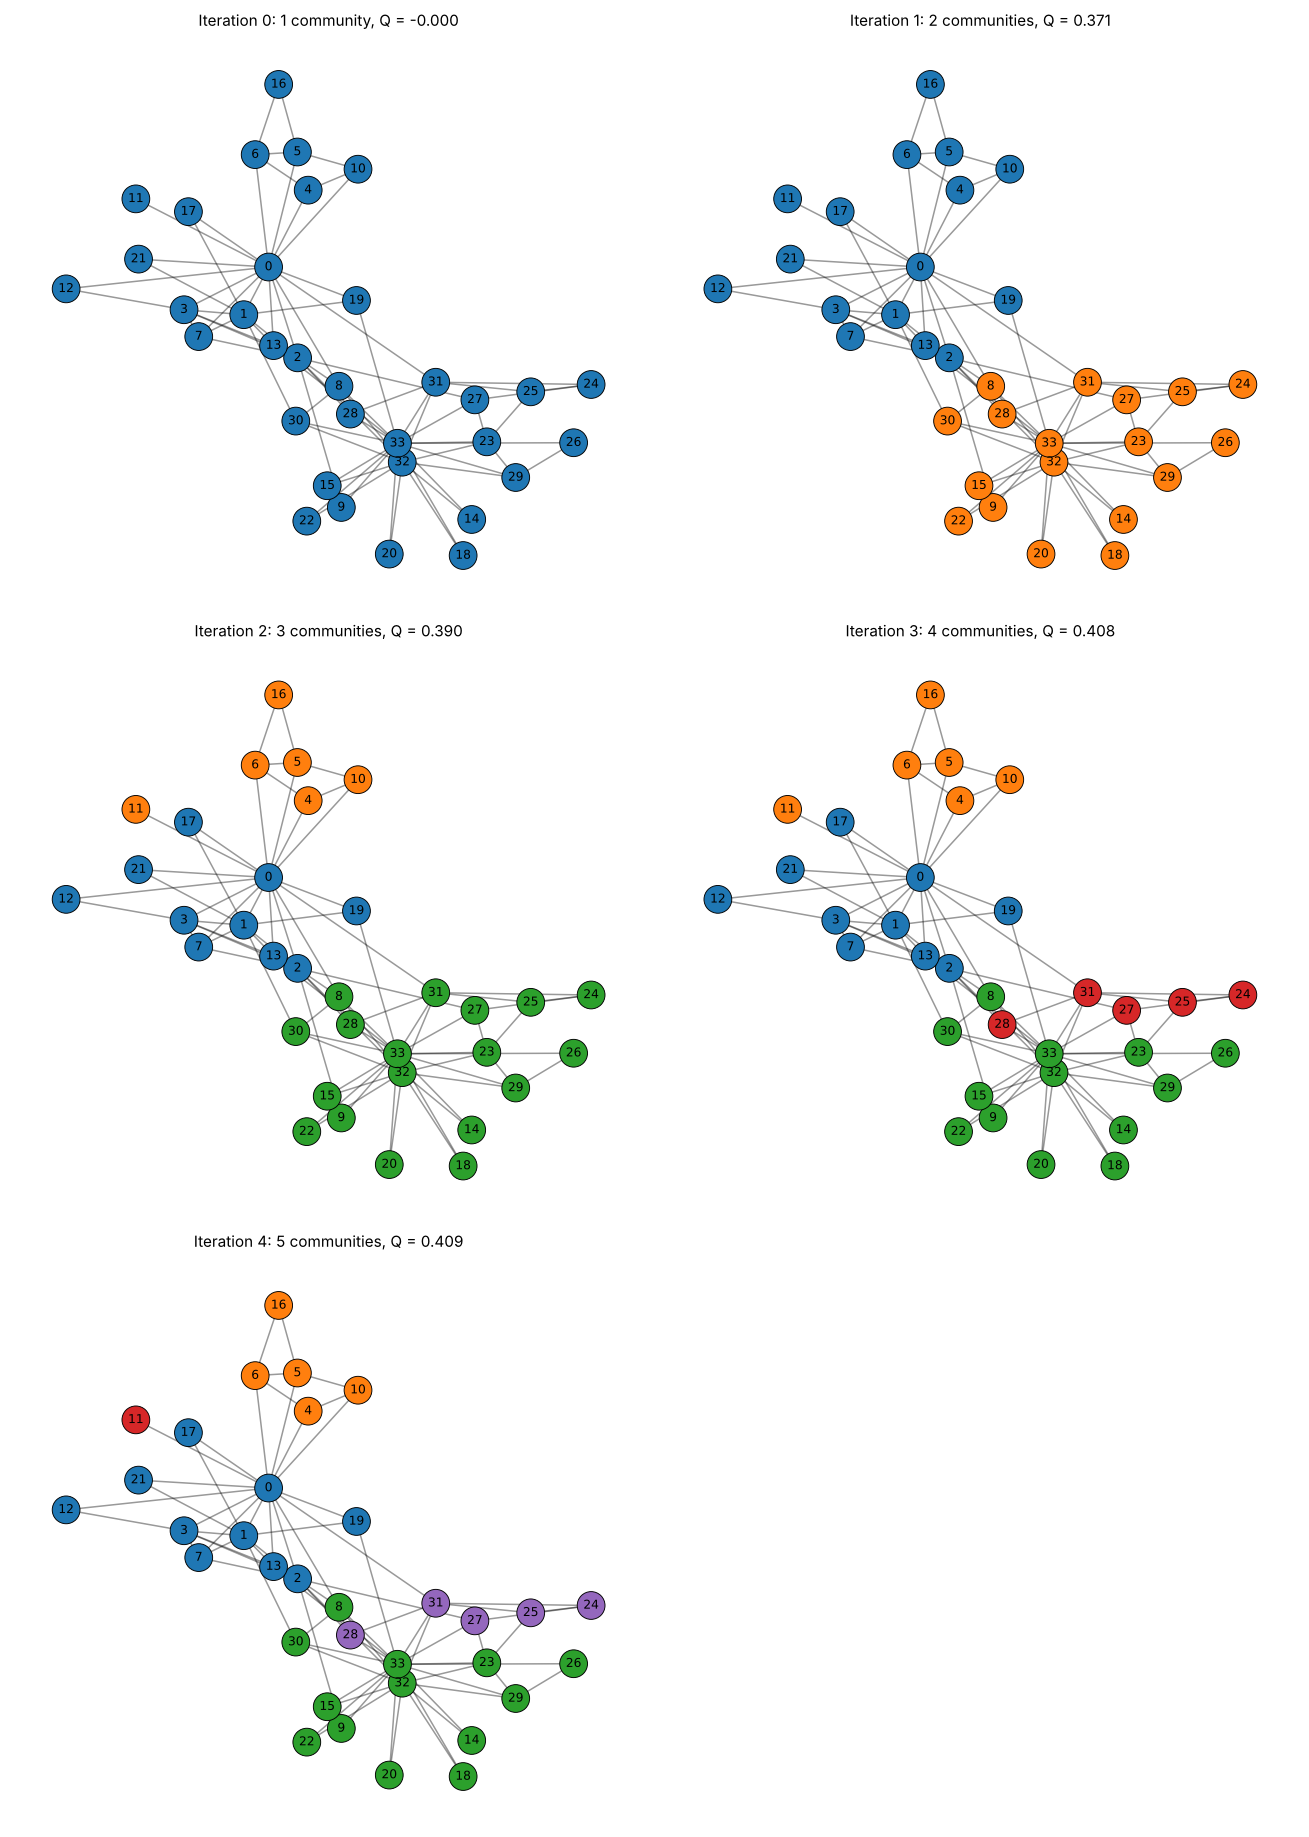

In [5]:
pos = nx.spring_layout(G, seed=42)
palette = plt.get_cmap('tab10')

def draw_partition(h, ax):
    comms = sorted(h['communities'], key=lambda c: min(c))
    color = {}
    for ci, c in enumerate(comms):
        for v in c: color[int(v)] = palette(ci % 10)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[color[v] for v in nodes], node_size=330, edgecolors='k', linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
    ax.set_title(f"Iteration {h['it']}: {len(comms)} communit{'y' if len(comms)==1 else 'ies'}, Q = {h['Q']:.3f}", fontsize=10)
    ax.axis('off')

ncols = 2
nrows = int(np.ceil(len(history)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5.6*nrows))
axes = np.atleast_1d(axes).ravel()
for ax, h in zip(axes, history): draw_partition(h, ax)
for ax in axes[len(history):]: ax.axis('off')
plt.tight_layout(); plt.savefig('partitions.png', bbox_inches='tight'); plt.show()

## 4. Node metrics after each split
For every iteration we compute, with NetworkX, degree/betweenness/closeness centrality and clustering coefficient.

*Design choice.* Computed on the **whole graph**, these four metrics would be identical at every iteration (the graph never changes; only the labels do). 
To measure how community structure influences them, we therefore compute each metric for node $i$ on the **subgraph induced by $i$'s current community** (its "within-community" metric). 
Iteration 0 is the full graph, so it doubles as the global baseline. Metrics are stored in a dictionary keyed by iteration number.

In [6]:
METRICS = {
    'Degree centrality': nx.degree_centrality,
    'Betweenness centrality': nx.betweenness_centrality,
    'Closeness centrality': nx.closeness_centrality,
    'Clustering coefficient': nx.clustering,
}

def metrics_for_partition(communities):
    out = {name: {} for name in METRICS}
    for c in communities:
        H = G.subgraph([int(v) for v in c])
        for name, f in METRICS.items():
            vals = f(H)
            for v in H.nodes(): out[name][v] = float(vals[v])
    return out

metric_hist = {h['it']: metrics_for_partition(h['communities']) for h in history}   # keyed by iteration
iters = sorted(metric_hist)
import pandas as pd
M = {name: pd.DataFrame({it: metric_hist[it][name] for it in iters}).sort_index() for name in METRICS}
M['Betweenness centrality'].round(3).head(10)

,0,1,2,3,4
0,0.438,0.690,0.354,0.354,0.354
1,0.054,0.074,0.215,0.215,0.215
2,0.144,0.002,0.007,0.007,0.007
3,0.012,0.021,0.062,0.062,0.062
4,0.001,0.003,0.050,0.050,0.083
5,0.030,0.065,0.150,0.150,0.250
6,0.030,0.065,0.150,0.150,0.250
7,0.000,0.000,0.000,0.000,0.000
8,0.056,0.000,0.000,0.000,0.000
9,0.001,0.000,0.000,0.000,0.000


## 5. Evolution of the metrics
For each metric: a line plot over iterations (the six highest-degree nodes are colored and labeled, the remaining nodes are in grey).

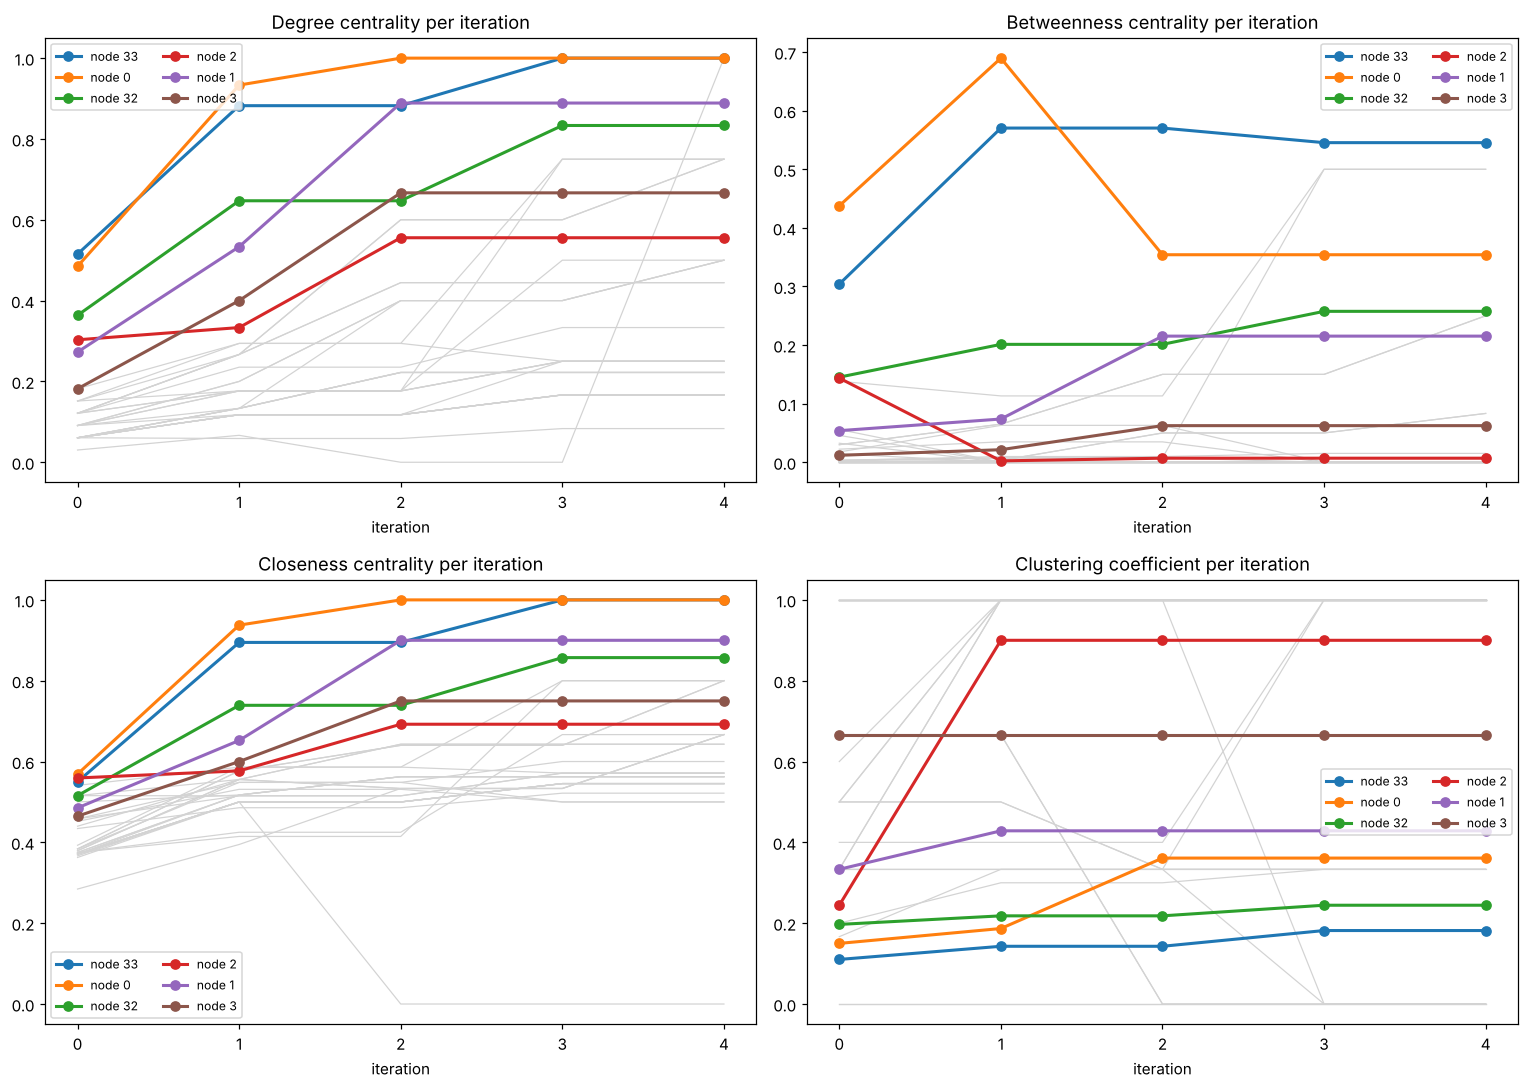

In [7]:
global_rank = nx.degree_centrality(G)
hubs = sorted(global_rank, key=global_rank.get, reverse=True)[:6]       # highest-degree nodes at iteration 0
hub_color = {h: plt.get_cmap('tab10')(i) for i, h in enumerate(hubs)}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, df) in zip(axes.ravel(), M.items()):
    for v in df.index:
        if v not in hubs: ax.plot(iters, df.loc[v], color='lightgrey', lw=0.8, zorder=1)
    for v in hubs: ax.plot(iters, df.loc[v], marker='o', color=hub_color[v], lw=2, label=f"node {v}", zorder=3)
    ax.set_title(name + " per iteration"); ax.set_xlabel("iteration"); ax.set_xticks(iters); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig('metric_evolution.png', bbox_inches='tight'); plt.show()

In [8]:
# Supporting numbers for the discussion
for name, df in M.items():
    top = df.apply(lambda col: col.nlargest(3).index.tolist())
    print(f"\n{name}: top-3 nodes per iteration")
    print(top.T.to_string())

# Consistency of centrality: how often is each node in the top-5 over iterations (degree & betweenness)?
for name in ['Degree centrality', 'Betweenness centrality', 'Closeness centrality']:
    counts = M[name].apply(lambda col: pd.Series(1, index=col.nlargest(5).index)).fillna(0).sum(axis=1)
    print(f"\n{name}: times in top-5 (out of {len(iters)} iterations):", counts[counts > 0].sort_values(ascending=False).astype(int).to_dict())
print("\nMean clustering coefficient per iteration:", M['Clustering coefficient'].mean().round(3).to_dict())
print("Mean closeness per iteration:", M['Closeness centrality'].mean().round(3).to_dict())


Degree centrality: top-3 nodes per iteration
    0   1   2
0  33   0  32
1   0  33  32
2   0   1  33
3   0  33   1
4   0  11  33

Betweenness centrality: top-3 nodes per iteration
    0   1   2
0   0  33  32
1   0  33  32
2  33   0   1
3  33  24  31
4  33  24  31

Closeness centrality: top-3 nodes per iteration
   0   1   2
0  0   2  33
1  0  33  32
2  0   1  33
3  0  33   1
4  0  33   1

Clustering coefficient: top-3 nodes per iteration
   0   1   2
0  7  12  14
1  7   8  12
2  7   8  12
3  7   8  12
4  7   8  12

Degree centrality: times in top-5 (out of 5 iterations): {0: 5, 1: 5, 32: 5, 33: 5, 3: 2, 2: 1, 24: 1, 11: 1}

Betweenness centrality: times in top-5 (out of 5 iterations): {0: 5, 33: 5, 32: 5, 31: 4, 1: 2, 24: 2, 5: 1, 2: 1}

Closeness centrality: times in top-5 (out of 5 iterations): {0: 5, 33: 5, 1: 4, 32: 4, 3: 2, 2: 1, 8: 1, 5: 1, 31: 1, 24: 1}

Mean clustering coefficient per iteration: {0: 0.571, 1: 0.684, 2: 0.64, 3: 0.641, 4: 0.641}
Mean closeness per iteration: {0

## 6. Extra check: Newman's generalized restricted matrix
The handout's $B^{(C)}$ is a plain block of $B$. Newman's generalized matrix adds a diagonal correction. Here we compare the final partitions and Q.

In [9]:
hist_g, final_g = recursive_bisection(B, m, generalized=True)
print("Handout block version  :", len(final), "communities, Q =", round(modularity(B, m, final), 4))
print("Newman generalized     :", len(final_g), "communities, Q =", round(modularity(B, m, final_g), 4))
print("\nGeneralized communities:")
for c in sorted(final_g, key=lambda c: min(c)): print(sorted(int(x) for x in c))

Handout block version  : 5 communities, Q = 0.4094
Newman generalized     : 5 communities, Q = 0.3776

Generalized communities:
[0, 4, 5, 6, 10, 11, 16]
[1, 17, 19, 21]
[2, 3, 7, 12, 13]
[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
[23, 24, 25, 27, 28, 31]


## 7. Discussion
*(All numbers are taken from the outputs above; the notebook prints them when run.)*

**Did the method recover the split?** Yes, almost exactly. The first spectral bisection ($\lambda_1 = 4.977$, $Q = 0.372$) uses only the graph structure and splits the club 16 / 18. 
It agrees with the real post-split factions for 33 of 34 members; the only misassigned member is node 8, who is known to be a borderline case (he has ties to both sides). 
So the friendship network recorded *before* the dispute already contained the fault line. 
Sanity checks pass: $B\mathbf 1 = 0$ to machine precision (Proposition 2), $Q = 0$ for the trivial partition (Corollary 1), and our $Q$ equals NetworkX's `modularity` on the final partition (0.4094).

**Further splits.** The recursion accepts a split only when the leading eigenvalue of $B^{(C)}$ is positive (Theorem 3) and stops after four splits, giving 5 communities with $Q = 0.409$. 
Almost all of the modularity comes from the first split (0.372); the next two splits add about 0.02 each and the last adds about 0.001. 
That last split just peels off node 11, a degree-1 leaf attached to node 0 ($\lambda_1 = 2.15$). It is a useful warning that a positive eigenvalue only means *some* gain exists, not that the gain is meaningful.
Section 6 shows that Newman's generalized restricted matrix (with the diagonal correction) also yields 5 communities but a different partition and a lower final $Q$ (0.378): it makes $\Delta Q$ exact for one group with the rest held fixed, but greedy bisection does not guarantee a higher final $Q$.

**Which nodes remain central?** Nodes **0** (Mr. Hi) and **33** (the president) are in the top 5 for degree, betweenness and closeness at *every* iteration, and node **32** is also in the top 5 for degree and betweenness at every iteration. 
They are hubs of their own communities, so cutting away the other side removes few of their links. 
Node **1** is a consistent hub of Mr. Hi's side (top 5 for degree in all iterations, for closeness in 4 of 5).
Betweenness shows which nodes are central only because of the whole-graph structure: node **2** has betweenness 0.144 on the full graph but 0.002 right after the first split, because it mainly lay on paths between the two factions. 
Node **0**'s betweenness peaks at 0.69 after the first split and falls to 0.35 once the pendant group {4, 5, 6, 10, 11, 16}, which reaches the rest only through node 0, is separated.

**How community structure shapes the metrics.**
- *Degree and closeness centrality* are normalised by the size of the current subgraph, so they rise as communities shrink: node 0 goes from 0.49 to 1.00 (adjacent to everyone in its 10-node community) and the mean closeness increases steadily from 0.426 to 0.639.
- *Betweenness* concentrates on within-community hubs and on nodes that tie small sub-groups together. After iteration 3, nodes 31 and 24 jump to 0.5 because they connect the small community {24, 25, 27, 28, 31}. This is an effect of measuring inside a tiny subgraph, not a global role.
- *Clustering* is local. Mean clustering rises from 0.571 to 0.684 after the first split (cross-community edges were sparse and unclustered) and then settles around 0.64. Node 2 jumps from 0.24 to 0.90 after the cut, while hubs 0 and 33 stay low (0.36 and 0.18 at the end) because their neighbours are mostly not adjacent to each other. Node 7 has clustering 1.0 throughout (its neighbours 0, 1, 2, 3 are mutually adjacent).
- *Artifact to be aware of:* when node 11 becomes a one-node community, NetworkX returns degree centrality 1.0 and closeness 0.0 for it by convention, which is why node 11 appears in the iteration-4 degree top 3. It is not a real hub.

Overall, hubs 0, 33 and 32 are central for two reasons: they are well connected and sit at the heart of their communities. 
Brokers such as node 2 are central only relative to the whole graph, and their centrality disappears once the inter-community edges they rely on are cut.

## References
1. M. E. J. Newman (2006). Modularity and community structure in networks. *PNAS* 103(23):8577–8582.
2. W. W. Zachary (1977). An information flow model for conflict and fission in small groups. *J. Anthropological Research* 33(4):452–473.